## Processamento de Linguagem Natural - Lista 02

Alunos
- Arthur Pontes de Miranda Ramos Soares
- Beatriz Rodrigues Cavalcante

## Execuções comuns

In [ ]:
# Instalar o BERTopic
# !pip install bertopic

In [2]:
import html
import re
from collections import Counter
from copy import deepcopy

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import torch
from bertopic import BERTopic
from bertopic.dimensionality import BaseDimensionalityReduction
from IPython.display import HTML, display
from nltk import word_tokenize
from nltk.corpus import stopwords
from nltk.stem.lancaster import LancasterStemmer
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import NMF, TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
from sklearn.svm import LinearSVC
from umap import UMAP

/home/arthurpmrs/dev/nlp-numerical-methods/nlp/.venv/lib64/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# Pegar base de dados do GitHub
# !mkdir -p assets
# !wget -q "https://raw.githubusercontent.com/Arthurpmrs/nlp-numerical-methods/refs/heads/main/nlp/data/songs_reduced.csv?raw=true" -O ./assets/songs_reduced.csv

In [34]:
# Funções comuns e download de bases do nltk
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("averaged_perceptron_tagger_eng")

stop_words = set(stopwords.words("english"))
stemmer = LancasterStemmer()

def preprocess_lyrics(text):
    if pd.isna(text):
        return ""

    text = text.lower()
    text = re.sub(r"\b\w*\d\w*\b", "", text)
    text = re.sub(r"[^\w\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()

    tokens = word_tokenize(text)
    stems = [
        stemmer.stem(token)
        for token in tokens
        if token not in stop_words
    ]

    return " ".join(stems)

def get_similarity_result(X_count, selected_indices) -> pd.DataFrame:
    results_count = []

    for idx in selected_indices:
        similarities = cosine_similarity(X_count[idx],X_count).flatten()

        similarities[idx] = -1

        most_similar_position = similarities.argmax()
        similarity_score = similarities[most_similar_position]

        results_count.append({
            "selected_index": idx,
            "similar_index": most_similar_position,
            "similarity": similarity_score
        })

    return pd.DataFrame(results_count).sort_values("similarity", ascending=False).reset_index(drop=True)

[nltk_data] Downloading package punkt to /home/arthurpmrs/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/arthurpmrs/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /home/arthurpmrs/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /home/arthurpmrs/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


In [5]:
# Ler dados como DataFrame
df = pd.read_csv("data/songs_reduced.csv")
df["preprocessed_lyrics"] = df["lyrics"].apply(preprocess_lyrics)

## Questão 1

In [6]:
# Selecionar 5 músicas aleatoriamente
selected_indices = df.sample(5, random_state=42).index

selected = df.loc[selected_indices]

selected[["artists", "name", "preprocessed_lyrics"]]

,artists,name,preprocessed_lyrics
10650,"[""The Strumbellas""]",In This Life,know season aint chang everyday look lik rain ...
2041,"[""Therion""]",Land of Canaan,noah curs cana liv serv teshub ang storm sweep...
8668,"[""Damian Marley""]",Julie,july on tru on lov best july break heart wel s...
1114,"[""The Beatles""]",Norwegian Wood (This Bird Has Flown) - Remaste...,girl say show room isnt good norweg wood ask s...
13902,"[""Demons & Wizards""]",Final Warning,doom test ther dant dea pass pump wav beat ins...


### a) CountVectorizer
Buscar letras mais semelhantes com base em CountVectorizer + Similaridade de Cossenos.

In [16]:
# Calcular matriz de documentos
texts = df["preprocessed_lyrics"].fillna("")

count_vectorizer = CountVectorizer(
    max_df=0.9,
    min_df=50,
    token_pattern=r"\b[a-z]{2,}\b"
)
X_count = count_vectorizer.fit_transform(texts)

print(X_count.shape)
pd.DataFrame(X_count.toarray(), columns=count_vectorizer.get_feature_names_out())

(20000, 3193)


,abandon,abl,absolv,abus,abyss,ac,acceiv,accid,account,ach,...,youl,young,youth,youv,yow,yuh,yup,zero,zip,zon
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,3,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
19996,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
19997,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
19998,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Aqui, o `max_df` e o `min_df` foram utilizados para remover as palavras presentes em mais de 90% dos documentos (pouca capacidade de diferenciação entre os textos) e palavras presentes em menos de 50 textos. Assim, removemos consideravelmente o tamanho da matriz, que antes tinha 66000 colunas, aproximadamente. O `token_pattern` foi utilizado para remover palavras escritas com caracteres de outros idiomas, mantendo apenas alfabeto latino.

In [18]:
# Calcular diferença de cossenos entre as 5 músicas selecionadas e todas as demais,
# excluíndo ela própria (Nota dada para a similaridade com ela mesma = -1)
results_count = get_similarity_result(X_count, selected_indices)
results_count

,selected_index,similar_index,similarity
0,1114,17919,1.000000
1,8668,10392,0.536512
2,10650,7011,0.491053
3,2041,8342,0.427856
4,13902,6956,0.395655


In [19]:
# Detalhes sobre as músicas escolhidas e as selecionadas como mais parecidas
print("-" * 60)
for _, row in results_count.iterrows():
    original = df.loc[row["selected_index"]]
    similar = df.loc[row["similar_index"]]

    print(f"Música escolhida: {original['name']} ({original['artists']})")
    print(f"Mais semelhante:  {similar['name']} ({similar['artists']})")
    print(f"Similaridade:     {row['similarity']:.4f}")
    print("-" * 60)

------------------------------------------------------------
Música escolhida: Norwegian Wood (This Bird Has Flown) - Remastered 2009 (["The Beatles"])
Mais semelhante:  Norwegian Wood (["Waylon Jennings"])
Similaridade:     1.0000
------------------------------------------------------------
Música escolhida: Julie (["Damian Marley"])
Mais semelhante:  One More (["Jimmy Cliff"])
Similaridade:     0.5365
------------------------------------------------------------
Música escolhida: In This Life (["The Strumbellas"])
Mais semelhante:  Something About You (["James Carter", "BCS"])
Similaridade:     0.4911
------------------------------------------------------------
Música escolhida: Land of Canaan (["Therion"])
Mais semelhante:  El Shaddai (["Michael Card"])
Similaridade:     0.4279
------------------------------------------------------------
Música escolhida: Final Warning (["Demons & Wizards"])
Mais semelhante:  Give It Up (["Kool & The Gang"])
Similaridade:     0.3957
-----------------

Observando os resultados apresentados acima, é possível perceber que uma das músicas escolhidas, "Norwegian Wood (This Bird Has Flown) - Remastered 2009" encontrou um par de semelhança perfeita, Norwegian Wood, apresentando coeficiente de similaridade igual a 1.

Apesar de a similaridade com o próprio texto não ter sido considerada como pede a atividade, aconteceu de selecionarmos (aleatoriamente) uma música que possuía uma regravação dentro da base. Como se trata de uma regravação, a musicalidade e o artista são diferentes, mas a letra é exatamente igual. Se a letra é exatamente igual, os vetores obtidos pelo `CountVectorizer` são também exatamente iguais, ou seja, possuem um ângulo entre eles igual a 0º e o cosseno de 0º é 1.

O segundo par de maior similaridade fora mas músicas "Julie" e "One More". Para verificar porque isso acontece, vamos listas os tokens mais comuns entre os pares de música, desconsiderando o caso de similaridade igual a 1.

In [20]:
def compare_cv_count_tokens(selected_index, similar_index, X_count, count_vectorizer):
    feature_names = count_vectorizer.get_feature_names_out()

    selected_counts = X_count[selected_index].toarray().ravel()
    similar_counts = X_count[similar_index].toarray().ravel()

    comparison = pd.DataFrame({
        "token": feature_names,
        "selected_count": selected_counts,
        "similar_count": similar_counts
    })

    comparison = comparison[
        (comparison["selected_count"] > 0) & (comparison["similar_count"] > 0)
    ].copy()
    comparison["count_product"] = comparison["selected_count"] * comparison["similar_count"]

    return comparison.sort_values("count_product", ascending=False).reset_index(drop=True)

In [21]:
# Apresentar os resultados apenas para os casos em que as letras não eram iguais
filtered_results_count = results_count[results_count['similarity'] < 0.999]
for _, row in filtered_results_count.iterrows():
    selected_index = int(row["selected_index"])
    similar_index = int(row["similar_index"])

    original_name = df.iloc[selected_index]["name"]
    similar_name = df.iloc[similar_index]["name"]

    comparison = compare_cv_count_tokens(
        selected_index,
        similar_index,
        X_count,
        count_vectorizer
    )

    print("-" * 60)
    print(f"{original_name} × {similar_name}")
    print(f"Similaridade: {row['similarity']:.4f}")
    print(f"Quantidade de tokens compartilhados: {len(comparison)}")

    display(comparison.head(10))

------------------------------------------------------------
Julie × One More
Similaridade: 0.5365
Quantidade de tokens compartilhados: 9


,token,selected_count,similar_count,count_product
0,on,17,47,799
1,run,4,2,8
2,lov,4,2,8
3,im,4,2,8
4,tru,5,1,5
5,away,4,1,4
6,baby,4,1,4
7,say,4,1,4
8,giv,1,1,1


------------------------------------------------------------
In This Life × Something About You
Similaridade: 0.4911
Quantidade de tokens compartilhados: 3


,token,selected_count,similar_count,count_product
0,someth,10,35,350
1,ther,10,9,90
2,keep,1,1,1


------------------------------------------------------------
Land of Canaan × El Shaddai
Similaridade: 0.4279
Quantidade de tokens compartilhados: 10


,token,selected_count,similar_count,count_product
0,el,9,15,135
1,yo,6,3,18
2,god,8,1,8
3,see,4,2,8
4,land,6,1,6
5,sea,6,1,6
6,son,3,2,6
7,nam,1,3,3
8,pra,1,3,3
9,tim,2,1,2


------------------------------------------------------------
Final Warning × Give It Up
Similaridade: 0.3957
Quantidade de tokens compartilhados: 9


,token,selected_count,similar_count,count_product
0,giv,6,21,126
1,com,4,6,24
2,dant,2,4,8
3,im,3,1,3
4,feel,3,1,3
5,flo,1,2,2
6,fin,2,1,2
7,see,1,2,2
8,mov,1,1,1


A similaridade de cossenos calcula o produto interno entre os vetores e divide pelo produto das normas.

$\cos(\theta) = \frac{A \cdot B}{||A|| ||B||}$

Ou seja, dado os vetores $a = (a_1, a_2)$ e $b = (b_1, b_2)$, no numerador seria $a_1 b_1 + a_2 b_2$. No caso do `CountVectorizer`, $a_i$ e $b_i$ são as quantidades de um determinado token em cada texto. Portanto, quando um token $i$ se repete muitas vezes nos dois textos, o produto entre suas contagens aumenta ($a_i b_i$), contribuíndo para um aumento na similaridade. Entretanto, apenas isso não garante uma similaridade maior, já que também é feita a divisão pelo produto das normas dos vetores.

No caso do par “Julie” e “One More”, o token "on" apareceu 17 vezes em uma das músicas e 47 na outra, resultando em um produto de contagens de 799. Somando as contribuições dos nove tokens compartilhados, o produto interno é 837. Portanto, esse único token representa aproximadamente 95,5% do numerador, sendo o principal responsável pela aproximação entre os vetores.

No par “In This Life” e “Something About You”, apenas três tokens são compartilhados. Mesmo assim, o token "someth", com contagens de 10 e 35, contribui com 350 para o produto interno, enquanto "ther" contribui com 90. Ou seja, vemos que não é necessário compartilhar muitos tokens quando os termos compartilhados têm bastante peso nos vetores.

No par “Land of Canaan” e “El Shaddai”, existem dez tokens compartilhados, mas a contribuição também está concentrada em um deles "el", com produto de 135. Os demais tokens, como "yo" e "god", acrescentam contribuições menores. Com isso, podemos perceber que compartilhar mais tokens não significa necessariamente obter uma similaridade maior.

Por fim, no par “Final Warning” e “Give It Up”, o token "giv", fornece a maior contribuição para o produto interno, sendo que o token com aparece em seguida, contribui consideravelmente. A similaridade menor entre os pares apresentados, acaba sendo influenciada pela relação entre o produto interno e as normas completas dos dois vetores, não apenas pela contagem.

Ou seja, aplicar a similaridade de cosseno com os vetores do `CountVectorizer` resulta em uma análise da frequência dos tokens em cada texto, dando maior similaridade aos textos que possuem um padrão de frequência mais próximo, ou seja, os que tem padrões de aparição de tokens mais parecidos.

### b) TF-IDF
Buscar letras mais semelhantes com base em TF-IDF + Similaridade de Cossenos

In [22]:
# Calcular matriz de documentos (usando os mesmos parâmetros do CountVectorizer)
tfidf_vectorizer = TfidfVectorizer(
    max_df=0.9,
    min_df=50,
    token_pattern=r"\b[a-z]{2,}\b"
)

X_tfidf = tfidf_vectorizer.fit_transform(texts)

print(X_tfidf.shape)

pd.DataFrame(X_tfidf.toarray(), columns=tfidf_vectorizer.get_feature_names_out())

(20000, 3193)


,abandon,abl,absolv,abus,abyss,ac,acceiv,accid,account,ach,...,youl,young,youth,youv,yow,yuh,yup,zero,zip,zon
0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.108287,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.058048,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
19996,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.011075,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
19997,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
19998,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [23]:
# Calcular diferença de cossenos entre as 5 músicas selecionadas e todas as demais
results_tfidf = get_similarity_result(X_tfidf, selected_indices)
results_tfidf

,selected_index,similar_index,similarity
0,1114,17919,1.000000
1,10650,7011,0.552297
2,2041,8342,0.528345
3,8668,4475,0.430334
4,13902,6860,0.262160


In [24]:
print("-" * 60)

for _, row in results_tfidf.iterrows():
    selected_index = int(row["selected_index"])
    similar_index = int(row["similar_index"])

    original = df.iloc[selected_index]
    similar = df.iloc[similar_index]

    print(f"Música escolhida: {original['name']} ({original['artists']})")
    print(f"Mais semelhante:  {similar['name']} ({similar['artists']})")
    print(f"Similaridade:      {row['similarity']:.4f}")
    print("-" * 60)

------------------------------------------------------------
Música escolhida: Norwegian Wood (This Bird Has Flown) - Remastered 2009 (["The Beatles"])
Mais semelhante:  Norwegian Wood (["Waylon Jennings"])
Similaridade:      1.0000
------------------------------------------------------------
Música escolhida: In This Life (["The Strumbellas"])
Mais semelhante:  Something About You (["James Carter", "BCS"])
Similaridade:      0.5523
------------------------------------------------------------
Música escolhida: Land of Canaan (["Therion"])
Mais semelhante:  El Shaddai (["Michael Card"])
Similaridade:      0.5283
------------------------------------------------------------
Música escolhida: Julie (["Damian Marley"])
Mais semelhante:  1000 Julys (["Third Eye Blind"])
Similaridade:      0.4303
------------------------------------------------------------
Música escolhida: Final Warning (["Demons & Wizards"])
Mais semelhante:  Storm in My Heart (["Dolores Keane"])
Similaridade:      0.2622
-

In [25]:
def compare_tfidf_tokens(selected_index, similar_index, X_tfidf, tfidf_vectorizer):
    feature_names = tfidf_vectorizer.get_feature_names_out()
    selected_weights = X_tfidf[selected_index].toarray().ravel()
    similar_weights = X_tfidf[similar_index].toarray().ravel()

    comparison = pd.DataFrame({
        "token": feature_names,
        "idf": tfidf_vectorizer.idf_,
        "selected_tfidf": selected_weights,
        "similar_tfidf": similar_weights
    })

    comparison = comparison[
        (comparison["selected_tfidf"] > 0) & (comparison["similar_tfidf"] > 0)
    ].copy()

    comparison["weight_product"] = (
        comparison["selected_tfidf"] * comparison["similar_tfidf"]
    )

    return comparison.sort_values("weight_product", ascending=False).reset_index(drop=True)

In [26]:
filtered_results_tfidf = results_tfidf[results_tfidf["similarity"] < 0.999]

for _, row in filtered_results_tfidf.iterrows():
    selected_index = int(row["selected_index"])
    similar_index = int(row["similar_index"])

    original_name = df.iloc[selected_index]["name"]
    similar_name = df.iloc[similar_index]["name"]

    comparison = compare_tfidf_tokens(selected_index, similar_index, X_tfidf, tfidf_vectorizer)

    print("=" * 60)
    print(f"{original_name} × {similar_name}")
    print(f"Similaridade: {row['similarity']:.4f}")
    print(f"Tokens compartilhados: {len(comparison)}")

    display(comparison.head(15))

In This Life × Something About You
Similaridade: 0.5523
Tokens compartilhados: 3


,token,idf,selected_tfidf,similar_tfidf,weight_product
0,someth,3.262934,0.486885,0.958754,0.466803
1,ther,2.740736,0.408965,0.207081,0.084689
2,keep,2.535309,0.037831,0.021284,0.000805


Land of Canaan × El Shaddai
Similaridade: 0.5283
Tokens compartilhados: 10


,token,idf,selected_tfidf,similar_tfidf,weight_product
0,el,5.580528,0.537425,0.858779,0.461530
1,sea,4.234039,0.271836,0.043438,0.011808
2,son,4.055532,0.130188,0.083213,0.010833
3,land,4.014965,0.257771,0.041190,0.010618
4,pra,5.173438,0.055358,0.159226,0.008814
5,yo,2.110988,0.135531,0.064971,0.008806
6,god,3.122399,0.267288,0.032033,0.008562
7,nam,3.159401,0.033807,0.097239,0.003287
8,see,1.933868,0.082773,0.039680,0.003284
9,tim,1.912349,0.040926,0.019619,0.000803


Julie × 1000 Julys
Similaridade: 0.4303
Tokens compartilhados: 9


,token,idf,selected_tfidf,similar_tfidf,weight_product
0,july,6.640858,0.744342,0.514304,0.382818
1,com,1.977817,0.110842,0.127644,0.014148
2,baby,2.664736,0.085336,0.103186,0.008806
3,mind,2.758858,0.110438,0.071220,0.007865
4,im,1.609316,0.051537,0.124634,0.006423
5,say,2.117845,0.067823,0.082009,0.005562
6,back,2.171394,0.034769,0.084082,0.002923
7,ev,2.314210,0.037056,0.029871,0.001107
8,giv,2.567387,0.020555,0.033139,0.000681


Final Warning × Storm in My Heart
Similaridade: 0.2622
Tokens compartilhados: 6


,token,idf,selected_tfidf,similar_tfidf,weight_product
0,storm,4.814493,0.306810,0.765084,0.234735
1,heart,2.506255,0.039929,0.398276,0.015903
2,word,3.214166,0.051207,0.102154,0.005231
3,wav,4.490079,0.071534,0.047569,0.003403
4,pul,3.520791,0.056092,0.037300,0.002092
5,back,2.171394,0.034594,0.023004,0.000796


Novamente desconsideramos o caso da música “Norwegian Wood”, pareada com sua regravação, pois os vetores gerados pelo TF-IDF são idênticos, assim como no caso do `CountVectorizer`, resultando em uma similaridade de cosseno igual a 1.

Nas tabelas acima foram apresentados os tokens de maior importância para a similaridade de cosseno com base no produto entre os coeficientes TF-IDF nos dois textos. Diferente do `CountVectorizer`, os coeficientes do TF-IDF incorporam tanto a frequência do token no texto quanto sua frequência entre os documentos da base, ou seja, tokens que aparecem em menos documentos recebem um IDF maior, pois podem ser melhores critérios de diferenciação.

No caso de “In This Life” e “Something About You”, o par formado foi o mesmo da análise com `CountVectorizer`, mas passou da segunda para a primeira posição entre os pares apresentados. Embora existam apenas três tokens compartilhados, `someth`, que possui pesos de 0,487 e 0,959, e `ther`, que apresenta pesos de 0.409 e 0.207, são os principais responsáveis pela similaridade. Mesmo tendo um IDF menor que os termos predominantes dos outros pares, a repetição de `someth` contribuiu para que ele tivesse bastante peso nos dois vetores, o que mostra que a frequência continua exercendo um papel significativo no TF-IDF.

No segundo colocado, “Land of Canaan” e “El Shaddai”, o par também se manteve em relação ao `CountVectorizer`, mas houve um aumento na similaridade. O token `el` apresenta um IDF de aproximadamente 5,58 e pesos de 0,537 e 0,859 nos dois textos e foi o principal responsável pela similaridade. Os demais 9 tokens apresentaram pouca influência nesse caso.

No terceiro colocado, “Julie” passou a formar par com “1000 Julys”, em vez de “One More”. O principal token compartilhado é `july`, que apresenta IDF de aproximadamente 6,64 e pesos de 0,744 e 0,514. Nota-se que houve uma mudança em relação ao par formado com "Julie" no `CountVectorizer`, cujo token de maior influência foi `on`. Apesar do IDF de `july` ser maior que o de `someth` e `el`, a frquência nos textos foi menor, o que mostra que a raridade não determina a similaridade sozinha.

Por fim, “Final Warning” passou a formar par com “Storm in My Heart”, em vez de “Give It Up”. O token `storm`, com IDF de aproximadamente 4,81, possui pesos de 0,307 e 0,765, foi o de maior influência. Os demais tokens compartilhados não apresentaram impacto significativo.

## Questão 2

### a) Rótulo dos documentos

A base já possui uma coluna `genre`, que será usada como rótulo do problema de classificação. Ela divide as músicas em 5 classes bem definidas e perfeitamente balanceadas.

In [28]:
# Preparar vetores de dados
X_text = df["preprocessed_lyrics"]
y = df["genre"]
df["genre"].value_counts()

genre
Hip-Hop    4000
Country    4000
Pop        4000
Rock       4000
Folk       4000
Name: count, dtype: int64

### b) Representações vetoriais

Os textos pré-processados (mesma limpeza usada na primeira lista: minúsculas, remoção de palavras com dígitos, remoção de pontuação, tokenização, remoção de stopwords e stemização) são vetorizados com `CountVectorizer` e `TfidfVectorizer`. Em ambos, `min_df=10` remove tokens muito raros e `max_df=0.9` remove tokens presentes em quase todos os documentos.

In [29]:
count_vectorizer = CountVectorizer(max_df=0.9, min_df=10)
X_count = count_vectorizer.fit_transform(X_text)

tfidf_vectorizer = TfidfVectorizer(max_df=0.9, min_df=10)
X_tfidf = tfidf_vectorizer.fit_transform(X_text)

print("CountVectorizer:", X_count.shape)
print("TfidfVectorizer:", X_tfidf.shape)

CountVectorizer: (20000, 8050)
TfidfVectorizer: (20000, 8050)


### c) Treino e avaliação

Foram escolhidos três classificadores: Regressão Logística, Naive Bayes e SVM linear. Cada classificador é treinado em cima das duas representações vetoriais, usando um split estratificado de 70% treino / 30% teste, como pedido na questão.

In [30]:
Xc_train, Xc_test, y_train, y_test = train_test_split(
    X_count, y, test_size=0.3, stratify=y, random_state=42
)
Xt_train, Xt_test, _, _ = train_test_split(
    X_tfidf, y, test_size=0.3, stratify=y, random_state=42
)

In [31]:
def train_and_evaluate(model, X_train, X_test, y_train, y_test, label):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision_micro = precision_score(y_test, y_pred, average="micro")
    precision_macro = precision_score(y_test, y_pred, average="macro")
    recall_micro = recall_score(y_test, y_pred, average="micro")
    recall_macro = recall_score(y_test, y_pred, average="macro")
    f1_micro = f1_score(y_test, y_pred, average="micro")
    f1_macro = f1_score(y_test, y_pred, average="macro")

    print(f"== {label} ==")
    print(f"Acurácia: {accuracy:.4f}")
    print(classification_report(y_test, y_pred))

    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, xticks_rotation=45)
    plt.title(label)
    plt.show()

    return {
        "modelo": label,
        "acuracia": accuracy,
        "precisao_micro": precision_micro,
        "precisao_macro": precision_macro,
        "recall_micro": recall_micro,
        "recall_macro": recall_macro,
        "f1_micro": f1_micro,
        "f1_macro": f1_macro,
    }

== Regressão Logística (CountVectorizer) ==
Acurácia: 0.5033
              precision    recall  f1-score   support

     Country       0.52      0.56      0.54      1200
        Folk       0.40      0.40      0.40      1200
     Hip-Hop       0.78      0.74      0.76      1200
         Pop       0.37      0.34      0.35      1200
        Rock       0.45      0.47      0.46      1200

    accuracy                           0.50      6000
   macro avg       0.50      0.50      0.50      6000
weighted avg       0.50      0.50      0.50      6000



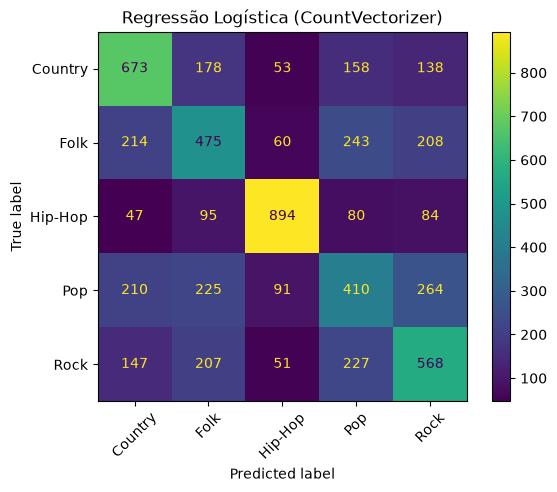

== Naive Bayes (CountVectorizer) ==
Acurácia: 0.5485
              precision    recall  f1-score   support

     Country       0.52      0.64      0.58      1200
        Folk       0.73      0.24      0.36      1200
     Hip-Hop       0.81      0.76      0.79      1200
         Pop       0.40      0.49      0.44      1200
        Rock       0.47      0.61      0.53      1200

    accuracy                           0.55      6000
   macro avg       0.59      0.55      0.54      6000
weighted avg       0.59      0.55      0.54      6000



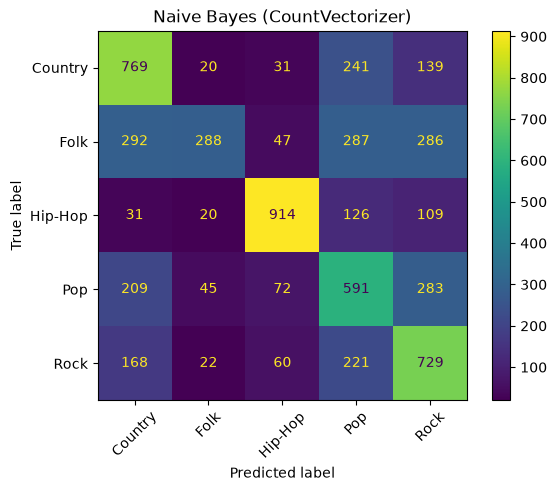

== SVM Linear (CountVectorizer) ==
Acurácia: 0.4968
              precision    recall  f1-score   support

     Country       0.50      0.57      0.53      1200
        Folk       0.40      0.39      0.40      1200
     Hip-Hop       0.76      0.74      0.75      1200
         Pop       0.38      0.33      0.35      1200
        Rock       0.44      0.45      0.44      1200

    accuracy                           0.50      6000
   macro avg       0.50      0.50      0.50      6000
weighted avg       0.50      0.50      0.50      6000



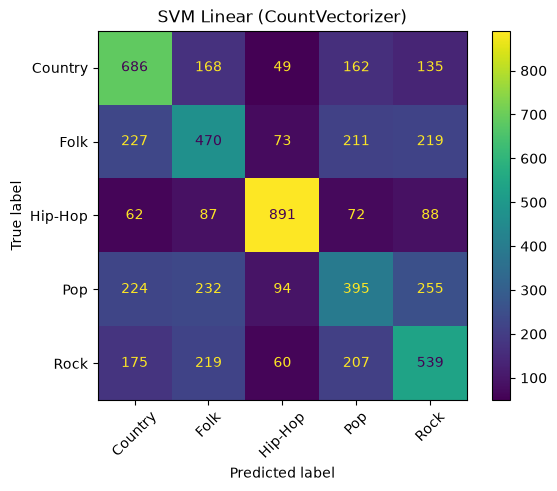

== Regressão Logística (TF-IDF) ==
Acurácia: 0.5648
              precision    recall  f1-score   support

     Country       0.57      0.63      0.60      1200
        Folk       0.48      0.40      0.44      1200
     Hip-Hop       0.83      0.80      0.82      1200
         Pop       0.42      0.44      0.43      1200
        Rock       0.52      0.55      0.54      1200

    accuracy                           0.56      6000
   macro avg       0.57      0.56      0.56      6000
weighted avg       0.57      0.56      0.56      6000



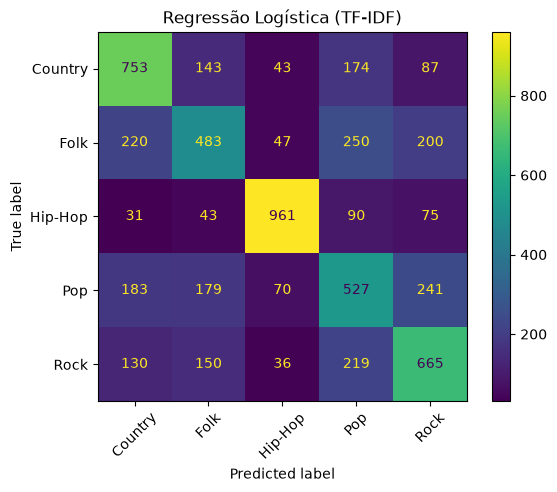

== Naive Bayes (TF-IDF) ==
Acurácia: 0.5605
              precision    recall  f1-score   support

     Country       0.50      0.72      0.59      1200
        Folk       0.62      0.28      0.39      1200
     Hip-Hop       0.80      0.78      0.79      1200
         Pop       0.42      0.48      0.45      1200
        Rock       0.54      0.54      0.54      1200

    accuracy                           0.56      6000
   macro avg       0.58      0.56      0.55      6000
weighted avg       0.58      0.56      0.55      6000



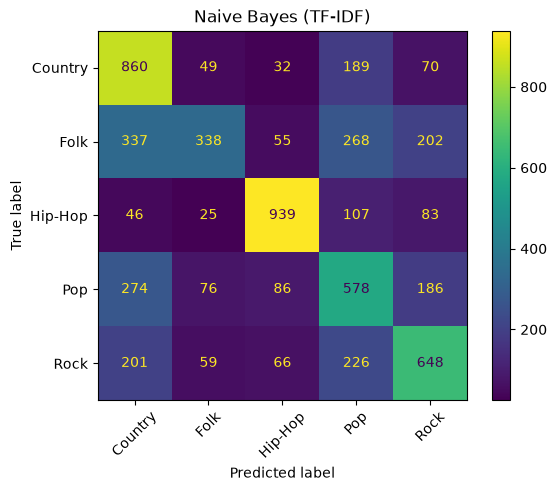

== SVM Linear (TF-IDF) ==
Acurácia: 0.5525
              precision    recall  f1-score   support

     Country       0.56      0.63      0.59      1200
        Folk       0.47      0.40      0.43      1200
     Hip-Hop       0.83      0.80      0.81      1200
         Pop       0.40      0.41      0.41      1200
        Rock       0.50      0.52      0.51      1200

    accuracy                           0.55      6000
   macro avg       0.55      0.55      0.55      6000
weighted avg       0.55      0.55      0.55      6000



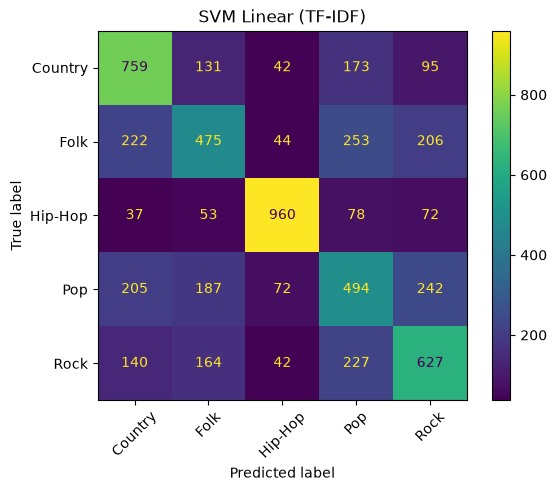

In [32]:
classifiers = {
    "Regressão Logística": LogisticRegression(max_iter=1000),
    "Naive Bayes": MultinomialNB(),
    "SVM Linear": LinearSVC(),
}

results = []

for name, model in classifiers.items():
    results.append(
        train_and_evaluate(
            model, Xc_train, Xc_test, y_train, y_test, f"{name} (CountVectorizer)"
        )
    )

for name, model in classifiers.items():
    results.append(
        train_and_evaluate(
            model, Xt_train, Xt_test, y_train, y_test, f"{name} (TF-IDF)"
        )
    )

### d) Comparação dos resultados
No geral, os três classificadores apresentaram desempenhos semelhantes em termos de acurácia, entre 49% e 56%, com pequenas variações dependendo da representação vetorial utilizada. A representação TF-IDF mostrou-se mais eficaz nos três modelos, tendo o melhor desempenho com a Regressão Linear. Já o CountVectorizer apresentou resultados mais consistentes com o Naive Bayes, enquanto o SVM linear teve um desempenho ligeiramente inferior em ambas as representações.

Observando as matrizes de confusão, percebe-se que algumas classes foram mais difíceis de classificar, como a classe "Pop", que teve uma taxa de acerto menor, enquanto o "Hip-Hop" apresentou uma taxa de acerto mais alta. Isso sugere que certas características textuais são mais distintivas para alguns gêneros musicais do que para outros, visto que as músicas da classe "Pop" podem abordar diversos temas, que podem ser facilmente confundidos com outros gêneros.

In [33]:
results_df = pd.DataFrame(results).sort_values("f1_macro", ascending=False).reset_index(drop=True)
results_df

,modelo,acuracia,precisao_micro,precisao_macro,recall_micro,recall_macro,f1_micro,f1_macro
0,Regressão Logística (TF-IDF),0.564833,0.564833,0.565804,0.564833,0.564833,0.564833,0.564124
1,Naive Bayes (TF-IDF),0.560500,0.560500,0.576624,0.560500,0.560500,0.560500,0.551755
2,SVM Linear (TF-IDF),0.552500,0.552500,0.552568,0.552500,0.552500,0.552500,0.551327
3,Naive Bayes (CountVectorizer),0.548500,0.548500,0.588089,0.548500,0.548500,0.548500,0.539653
4,Regressão Logística (CountVectorizer),0.503333,0.503333,0.503743,0.503333,0.503333,0.503333,0.503169
5,SVM Linear (CountVectorizer),0.496833,0.496833,0.495156,0.496833,0.496833,0.496833,0.495121


## Questão 3